In [11]:
import pandas as pd

df = pd.read_csv("../data/processed/sovereign_spreads_clean.csv")

df.head()

,Country,Year,Spread_bp,Debt_GDP,Fiscal_Balance,Real_GDP_Growth,Inflation,Unemployment,Current_Account,Interest_Payments,Primary_Balance
0,AT,2000,29.541667,66.6,-2.4,3.2,2.0,3.883333,-0.7,3.6,1.2
1,AT,2001,26.727500,67.2,-0.7,1.3,2.3,4.008333,-0.8,3.6,2.9
2,AT,2002,16.008333,67.4,-1.4,1.5,1.7,4.391667,2.1,3.5,2.1
3,AT,2003,4.691667,66.4,-1.8,1.1,1.3,4.791667,1.6,3.2,1.4
4,AT,2004,5.658333,65.9,-4.9,2.6,2.0,5.875000,2.1,3.1,-1.8


In [13]:

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 234 entries, 0 to 233
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Country            234 non-null    str    
 1   Year               234 non-null    int64  
 2   Spread_bp          234 non-null    float64
 3   Debt_GDP           234 non-null    float64
 4   Fiscal_Balance     234 non-null    float64
 5   Real_GDP_Growth    234 non-null    float64
 6   Inflation          234 non-null    float64
 7   Unemployment       234 non-null    float64
 8   Current_Account    234 non-null    float64
 9   Interest_Payments  234 non-null    float64
 10  Primary_Balance    234 non-null    float64
dtypes: float64(9), int64(1), str(1)
memory usage: 20.2 KB


In [14]:
df.describe()


,Year,Spread_bp,Debt_GDP,Fiscal_Balance,Real_GDP_Growth,Inflation,Unemployment,Current_Account,Interest_Payments,Primary_Balance
count,234.000000,234.000000,234.000000,234.000000,234.000000,234.000000,234.000000,234.000000,234.000000,234.000000
mean,2012.500000,114.693048,91.962821,-3.500000,1.773504,2.245299,9.196241,-0.284188,2.890598,-0.609402
std,7.516077,234.625768,36.744317,3.911818,3.761926,1.964033,4.822109,5.187378,1.381514,3.793160
min,2000.000000,-0.500000,23.700000,-32.100000,-10.900000,-1.700000,3.133333,-20.700000,0.500000,-29.300000
25%,2006.000000,20.906250,64.225000,-5.200000,0.700000,1.100000,5.987500,-1.900000,1.900000,-2.500000
50%,2012.500000,41.104167,95.700000,-3.100000,1.800000,2.150000,8.133333,0.450000,2.800000,0.000000
75%,2019.000000,99.743750,109.850000,-0.800000,3.175000,3.000000,10.593750,2.300000,3.600000,1.800000
max,2025.000000,2213.150000,209.400000,4.900000,24.600000,11.600000,27.808333,17.100000,7.700000,6.800000


In [15]:
df.loc[df["Spread_bp"].idxmax()]

Country                     GR
Year                      2012
Spread_bp              2213.15
Debt_GDP                 164.1
Fiscal_Balance            -9.3
Real_GDP_Growth           -8.3
Inflation                  1.0
Unemployment         24.833333
Current_Account           -3.6
Interest_Payments          5.4
Primary_Balance           -3.9
Name: 116, dtype: object

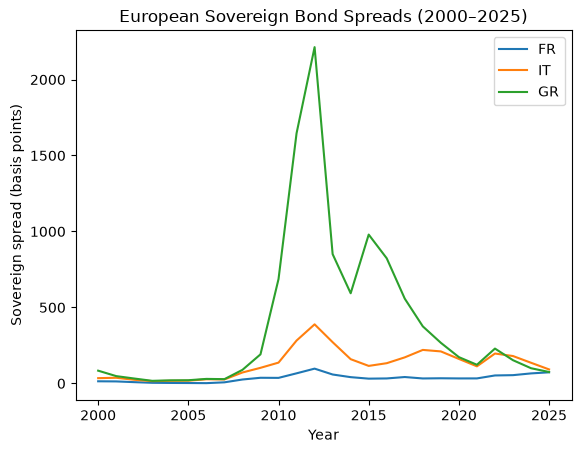

In [16]:
import matplotlib.pyplot as plt

countries = ["FR", "IT", "GR"]

for country in countries:
    data = df[df["Country"] == country]
    plt.plot(data["Year"], data["Spread_bp"], label=country)

plt.xlabel("Year")
plt.ylabel("Sovereign spread (basis points)")
plt.title("European Sovereign Bond Spreads (2000–2025)")
plt.legend()
plt.show()

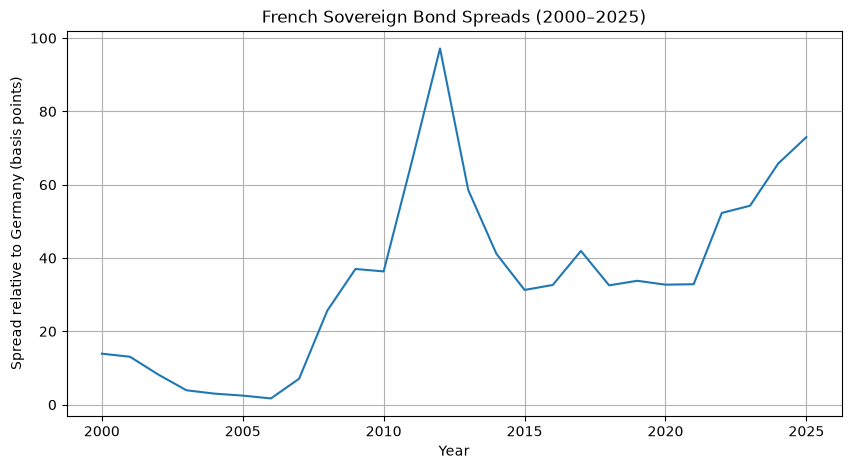

In [17]:
france = df[df["Country"] == "FR"]

plt.figure(figsize=(10, 5))
plt.plot(france["Year"], france["Spread_bp"])

plt.title("French Sovereign Bond Spreads (2000–2025)")
plt.xlabel("Year")
plt.ylabel("Spread relative to Germany (basis points)")
plt.grid(True)

plt.show()

In [18]:
correlations = df.corr(numeric_only=True)["Spread_bp"]

print(correlations.sort_values(ascending=False))

Spread_bp            1.000000
Unemployment         0.635655
Debt_GDP             0.522171
Interest_Payments    0.366283
Year                 0.093081
Inflation           -0.127658
Current_Account     -0.166587
Primary_Balance     -0.225724
Fiscal_Balance      -0.348235
Real_GDP_Growth     -0.355424
Name: Spread_bp, dtype: float64


In [19]:
df_no_greece = df[df["Country"] != "GR"]

correlations_no_greece = (
    df_no_greece
    .corr(numeric_only=True)["Spread_bp"]
    .sort_values(ascending=False)
)

print(correlations_no_greece)

Spread_bp            1.000000
Unemployment         0.558117
Debt_GDP             0.460229
Interest_Payments    0.332883
Year                 0.137744
Inflation           -0.080679
Current_Account     -0.127423
Real_GDP_Growth     -0.222911
Primary_Balance     -0.338481
Fiscal_Balance      -0.453546
Name: Spread_bp, dtype: float64


In [20]:
features = [
    "Debt_GDP",
    "Fiscal_Balance",
    "Real_GDP_Growth",
    "Inflation",
    "Unemployment",
    "Current_Account",
    "Interest_Payments"
]

df[features].corr().round(2)

,Debt_GDP,Fiscal_Balance,Real_GDP_Growth,Inflation,Unemployment,Current_Account,Interest_Payments
Debt_GDP,1.00,-0.33,-0.27,-0.19,0.57,-0.23,0.55
Fiscal_Balance,-0.33,1.00,0.40,0.21,-0.43,0.32,-0.26
Real_GDP_Growth,-0.27,0.40,1.00,0.23,-0.24,0.12,-0.21
Inflation,-0.19,0.21,0.23,1.00,-0.33,-0.10,-0.12
Unemployment,0.57,-0.43,-0.24,-0.33,1.00,-0.23,0.34
Current_Account,-0.23,0.32,0.12,-0.10,-0.23,1.00,-0.32
Interest_Payments,0.55,-0.26,-0.21,-0.12,0.34,-0.32,1.00


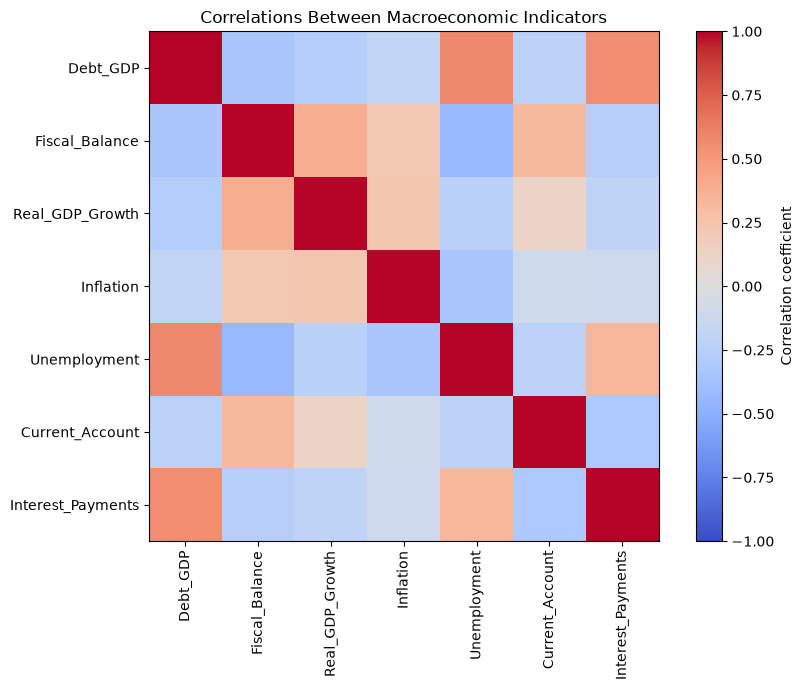

In [21]:
import matplotlib.pyplot as plt

corr_matrix = df[features].corr()

plt.figure(figsize=(9, 7))
plt.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(label="Correlation coefficient")
plt.xticks(range(len(features)), features, rotation=90)
plt.yticks(range(len(features)), features)

plt.title("Correlations Between Macroeconomic Indicators")
plt.tight_layout()
plt.show()